# Send Ubiq genes to Go terms to see if it can categorize them by function.
## Data set is version2d Nov
## TFs are Ensembl ID derived

# Used in Version 9

# This code was run on my laptop, not Sherlock system. Set this up to be run on Sherlock, for the GIT HUB version but never actually ran it. Need to add gseapy to conda env. Also there is a seed for random trials that changes so the result will not be exactly this same when re-run.  10-20-26

## General Import Functions

In [38]:
import pandas as pd

import scipy.stats as stats
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns

In [43]:
DATA_IN_DIR = '/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/'
DATA_OUT_DIR = '/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/'
TAU_VALUES = 'TauValuesCelltype.csv'
DATA_BP = 'GoAnalysisV9/RawTable5V9_UbiqGenesGOBiologicalProcesses2021.csv'


In [40]:
# get all TFs to use as background to within which to look for enrichment of low TF's
all_TFs = list(pd.read_csv(DATA_IN_DIR+TFxCT_DATA, index_col = 0).columns)
TauVals = pd.read_csv(DATA_IN_DIR+TAU_VALUES, index_col = 0)
all_TFs = TauVals.index.astype(str).tolist()

In [41]:
lowTaus = TauVals[TauVals.tau < 0.85]
print(len(lowTaus))
gene_list_of_interest = lowTaus.index.astype(str).tolist()

745


In [42]:
import gseapy
#Available databases : 'Human', 'Mouse', 'Yeast', 'Fly', 'Fish', 'Worm' 
gene_set_names = gseapy.get_library_name()
#print(gene_set_names)

ModuleNotFoundError: No module named 'gseapy'

In [55]:
# Set the random seed 
np.random.seed(42)

In [56]:
enr_res = gseapy.enrichr(gene_list=gene_list_of_interest, 
     organism='Human',
     gene_sets=['GO_Biological_Process_2021'],
     description='pathway', 
     #min_size = 5,
     #max_size = 500,                    
     background = all_TFs,
     cutoff = 0.01)

In [57]:
GO_results = enr_res.results
GO_results['Overlap'] = '_' + GO_results['Overlap']
print(DATA_OUT_DIR+DATA_BP)
#GO_results.to_csv(DATA_OUT_DIR+DATA_BP)

GO_results.head(70)

/Users/bob/Documents/TFanalysisManuscriptWrap11-11-2024/Fig2V9_Enrichr/RawTable3V9_UbiqGenesGOBiologicalProcesses2021.csv


,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2021,regulation of transcription by RNA polymerase ...,_609/2206,0.000000e+00,0.000000e+00,0,0,49.512514,inf,ATF1;ATF2;ZNF174;ZNF292;RBPJ;BACH1;ELK3;ELK4;Z...
1,GO_Biological_Process_2021,"regulation of transcription, DNA-templated (GO...",_623/2244,0.000000e+00,0.000000e+00,0,0,55.551532,inf,ATF1;ATF2;ZNF174;ZNF292;RBPJ;BACH1;ELK3;ELK4;Z...
2,GO_Biological_Process_2021,"negative regulation of transcription, DNA-temp...",_235/948,3.851868e-133,2.759222e-130,0,0,11.982977,3653.552939,ZNF174;RBPJ;BACH1;IKZF4;ELK3;IKZF5;ELK4;ZNF608...
3,GO_Biological_Process_2021,negative regulation of transcription by RNA po...,_192/684,1.177287e-117,6.324974e-115,0,0,13.240771,3564.935155,ZNF451;ZNF692;ZNF174;ZBTB21;PRDM2;RBPJ;NR3C1;B...
4,GO_Biological_Process_2021,"positive regulation of transcription, DNA-temp...",_228/1183,8.784927e-104,3.775762e-101,0,0,8.450687,2005.312661,ATF1;ATF2;RBPJ;ELK3;ELK4;ZXDA;ZNF609;MSANTD1;C...
...,...,...,...,...,...,...,...,...,...,...
65,GO_Biological_Process_2021,negative regulation of oxidative stress-induce...,_4/11,5.110839e-04,1.639283e-02,0,0,14.843262,112.496737,REST;NR4A3;HIF1A;ATF4
66,GO_Biological_Process_2021,positive regulation of DNA methylation-depende...,_4/11,5.110839e-04,1.639283e-02,0,0,14.843262,112.496737,DNMT1;SETDB1;SETDB2;ZNF304
67,GO_Biological_Process_2021,response to peptide (GO:1901652),_7/39,5.253862e-04,1.660375e-02,0,0,5.697874,43.026797,STAT5A;STAT5B;STAT1;STAT2;STAT3;KAT7;STAT6
68,GO_Biological_Process_2021,negative regulation of cell cycle process (GO:...,_9/64,5.785732e-04,1.790998e-02,0,0,4.268775,31.823483,PCGF6;TFDP1;TFDP2;MAX;MGA;PCGF2;TERF1;TERF2;E2F6


In [58]:
topTerms = GO_results[GO_results['Adjusted P-value'] < 0.02]
print(len(topTerms))
topTerms

70


,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2021,regulation of transcription by RNA polymerase ...,_609/2206,0.000000e+00,0.000000e+00,0,0,49.512514,inf,ATF1;ATF2;ZNF174;ZNF292;RBPJ;BACH1;ELK3;ELK4;Z...
1,GO_Biological_Process_2021,"regulation of transcription, DNA-templated (GO...",_623/2244,0.000000e+00,0.000000e+00,0,0,55.551532,inf,ATF1;ATF2;ZNF174;ZNF292;RBPJ;BACH1;ELK3;ELK4;Z...
2,GO_Biological_Process_2021,"negative regulation of transcription, DNA-temp...",_235/948,3.851868e-133,2.759222e-130,0,0,11.982977,3653.552939,ZNF174;RBPJ;BACH1;IKZF4;ELK3;IKZF5;ELK4;ZNF608...
3,GO_Biological_Process_2021,negative regulation of transcription by RNA po...,_192/684,1.177287e-117,6.324974e-115,0,0,13.240771,3564.935155,ZNF451;ZNF692;ZNF174;ZBTB21;PRDM2;RBPJ;NR3C1;B...
4,GO_Biological_Process_2021,"positive regulation of transcription, DNA-temp...",_228/1183,8.784927e-104,3.775762e-101,0,0,8.450687,2005.312661,ATF1;ATF2;RBPJ;ELK3;ELK4;ZXDA;ZNF609;MSANTD1;C...
...,...,...,...,...,...,...,...,...,...,...
65,GO_Biological_Process_2021,negative regulation of oxidative stress-induce...,_4/11,5.110839e-04,1.639283e-02,0,0,14.843262,112.496737,REST;NR4A3;HIF1A;ATF4
66,GO_Biological_Process_2021,positive regulation of DNA methylation-depende...,_4/11,5.110839e-04,1.639283e-02,0,0,14.843262,112.496737,DNMT1;SETDB1;SETDB2;ZNF304
67,GO_Biological_Process_2021,response to peptide (GO:1901652),_7/39,5.253862e-04,1.660375e-02,0,0,5.697874,43.026797,STAT5A;STAT5B;STAT1;STAT2;STAT3;KAT7;STAT6
68,GO_Biological_Process_2021,negative regulation of cell cycle process (GO:...,_9/64,5.785732e-04,1.790998e-02,0,0,4.268775,31.823483,PCGF6;TFDP1;TFDP2;MAX;MGA;PCGF2;TERF1;TERF2;E2F6


terms < 0.2 adj_Pval = 70


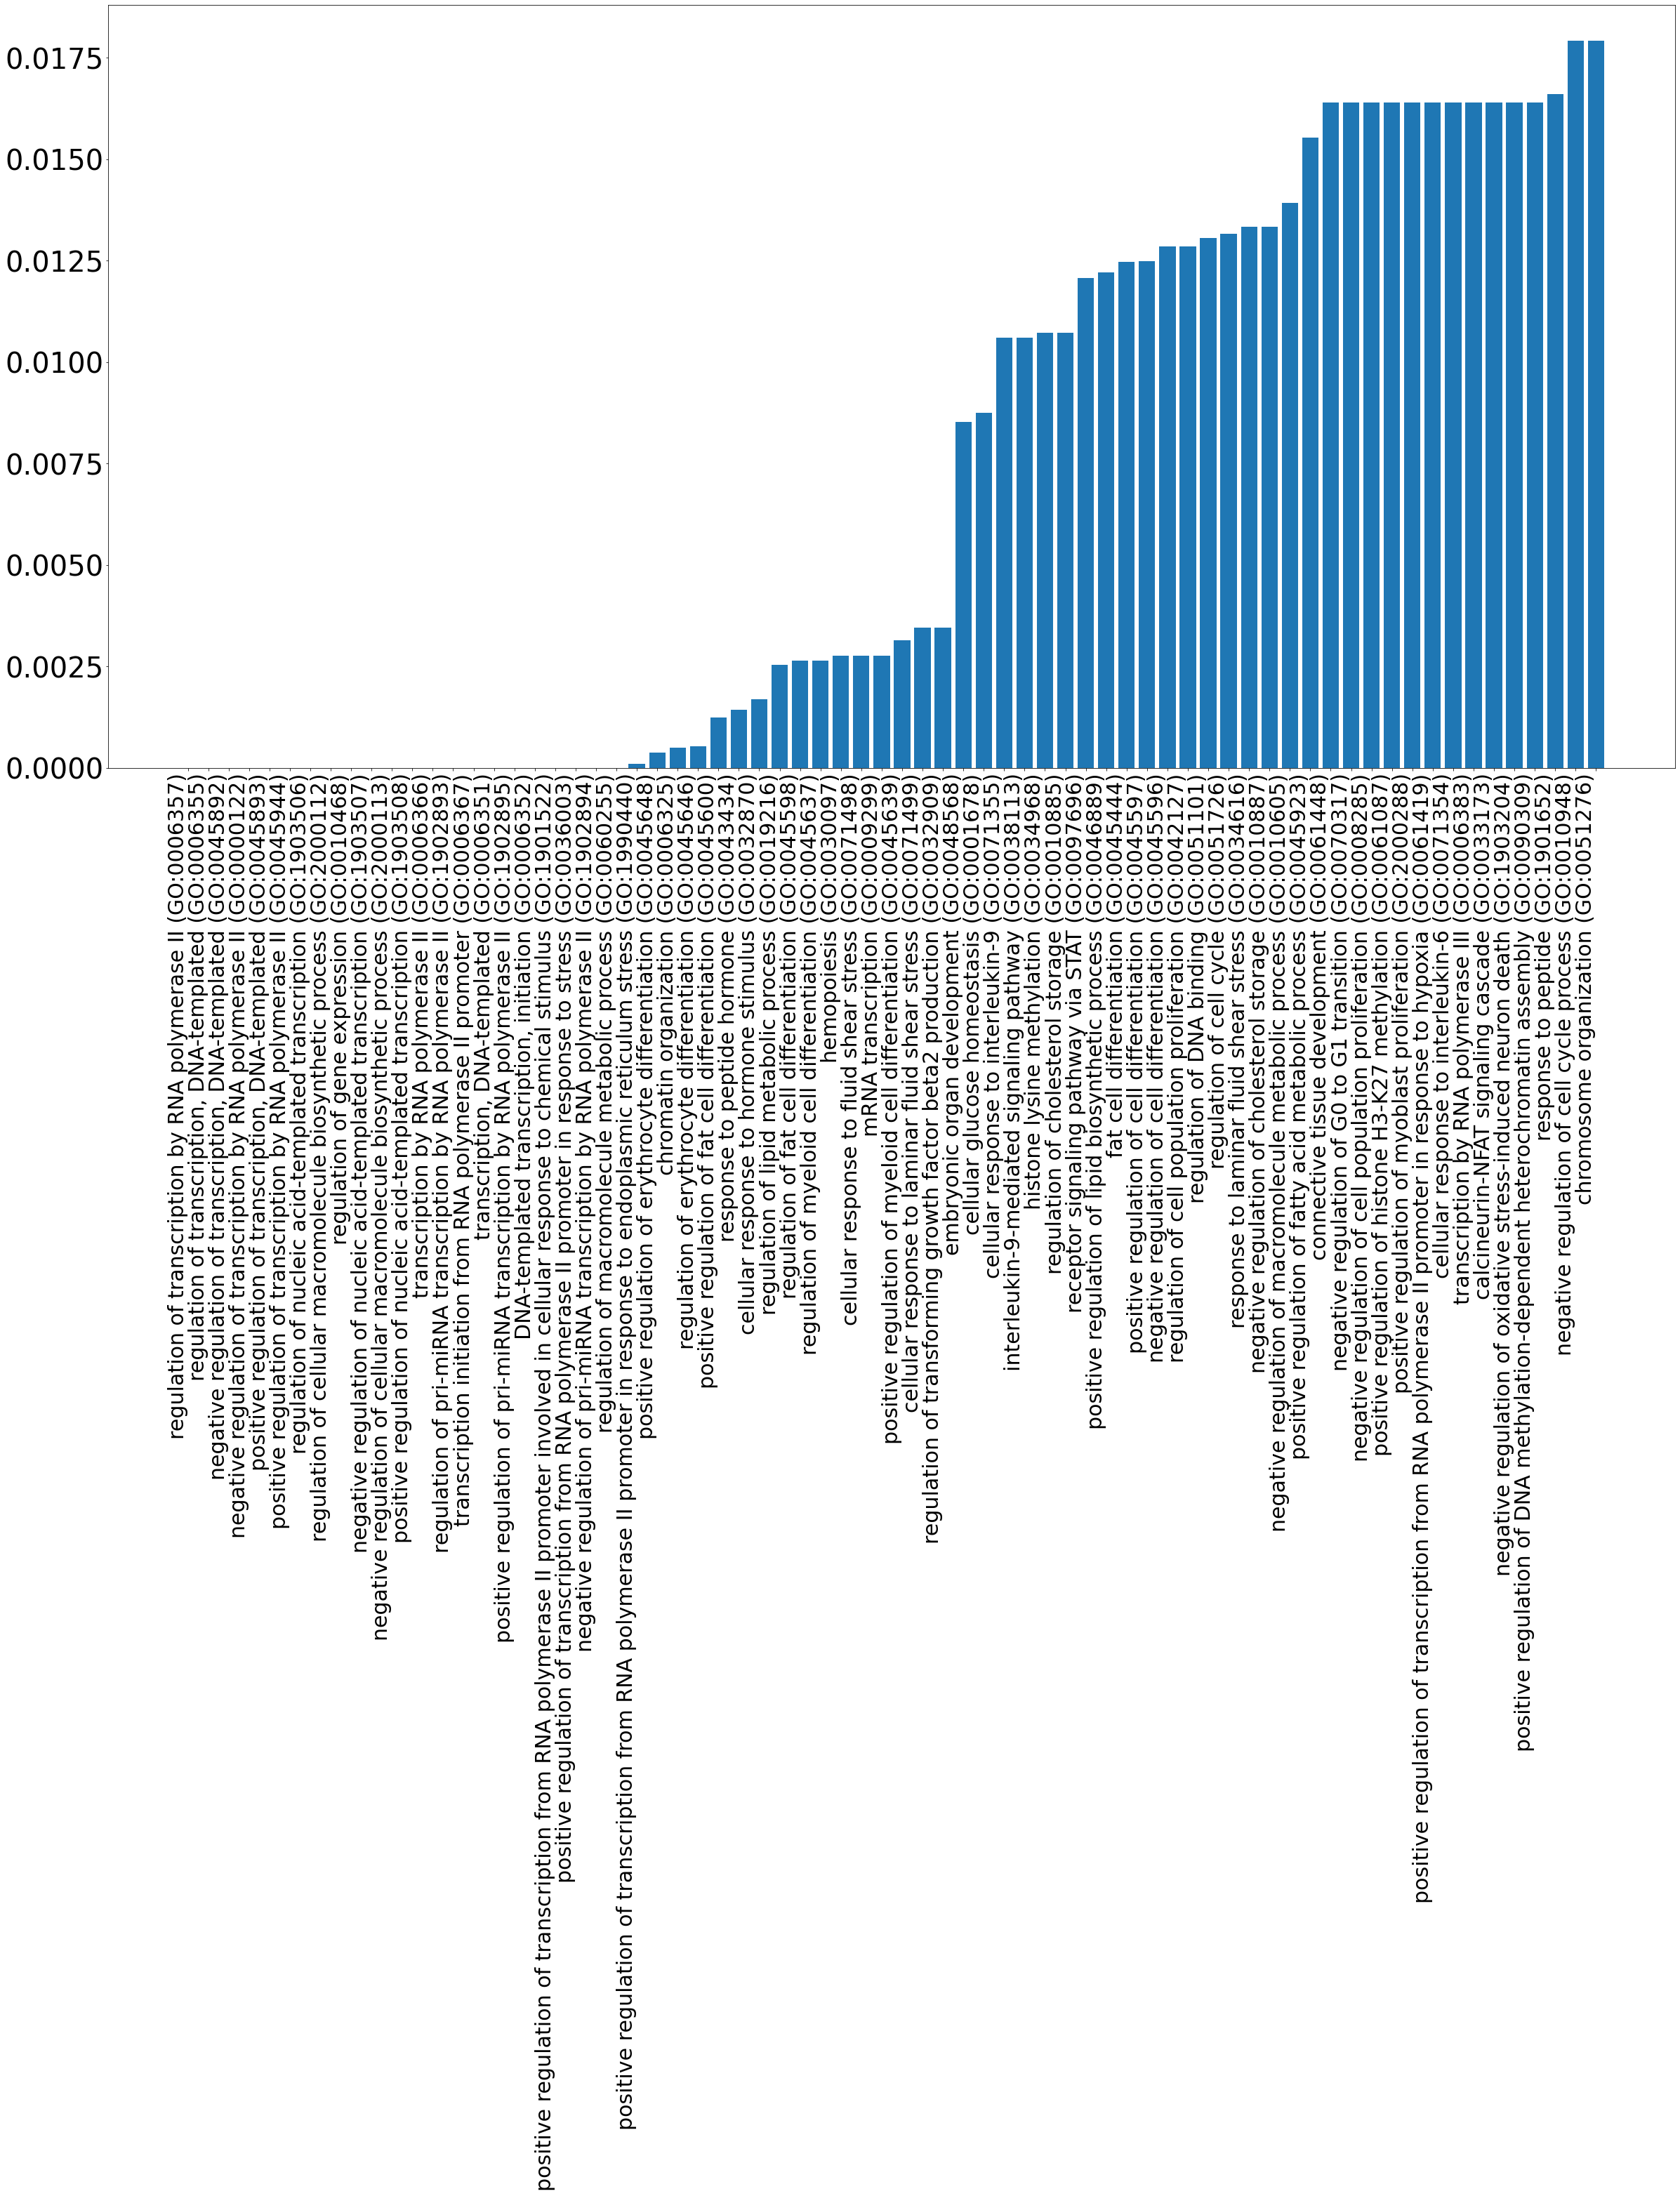

70

In [59]:
# Figure Size
print('terms < 0.2 adj_Pval =', len(topTerms))

fig, ax = plt.subplots(figsize = (40, 20))

# Horizontal Bar Plot
ax.bar(topTerms.Term, topTerms['Adjusted P-value'])

ax.tick_params(axis='x', labelsize=30)
ax.tick_params(axis='y', labelsize=40)
for label in ax.get_xticklabels():
  label.set_rotation(90)
  label.set_ha('right')
    
# Show Plot
plt.show()
len(topTerms)